# LAB 04 — Text Classification trên IMDb

Pipeline: `raw text → preprocessing → representation (TF-IDF | Avg Word2Vec) → classifier → evaluation → error analysis`.

Quy ước chống data leakage: mọi thành phần có *fit* (TfidfVectorizer, StandardScaler, Word2Vec, classifier) chỉ được fit trên **train**; validation dùng để chọn siêu tham số `C`; **test** chỉ dùng để báo cáo kết quả cuối.

In [ ]:
import warnings, time, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, precision_recall_fscore_support)
from gensim.models import Word2Vec

import preprocessing as P

np.random.seed(P.SEED)
sns.set_theme(style="whitegrid")
rows = []   # gom kết quả -> results.csv

def metrics(y, pred):
    return dict(accuracy=accuracy_score(y, pred),
                precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0))

def log(experiment, representation, classifier, split, size, t, m):
    rows.append(dict(experiment=experiment, representation=representation, classifier=classifier,
                     split=split, feature_dim=size, train_time_s=round(t, 3),
                     **{k: round(v, 4) for k, v in m.items()}))

## 1. Experiment 1 — Dataset inspection (chưa train gì)

train: (25000, 2) | test: (25000, 2)
Số classes: [np.int64(0), np.int64(1)] (0 = negative, 1 = positive)

[train] missing text: 0 | empty text: 0 | missing label: 0
[train] duplicate texts: 96

[test] missing text: 0 | empty text: 0 | missing label: 0
[test] duplicate texts: 199


,split,class_,count,percentage
0,train,negative,12500,50.0
1,train,positive,12500,50.0
2,test,negative,12500,50.0
3,test,positive,12500,50.0



Độ dài (số từ) train:


count    25000.0
mean       233.8
std        173.7
min         10.0
25%        127.0
50%        174.0
75%        284.0
max       2470.0
Name: n_words, dtype: float64

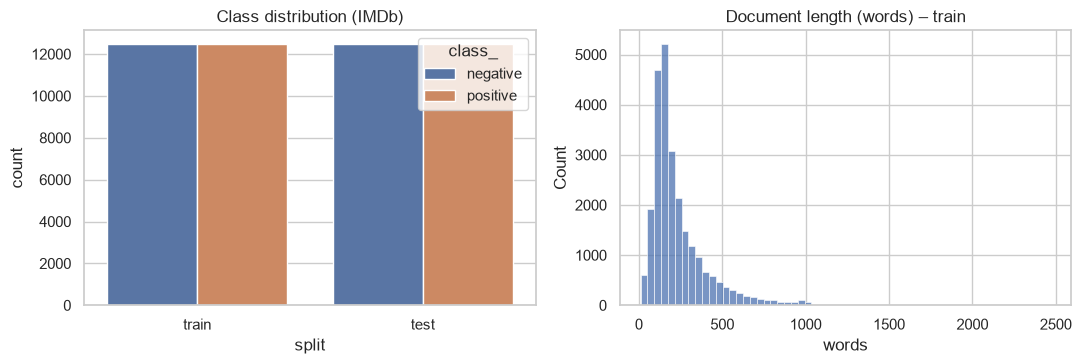

Số review xuất hiện ở cả train lẫn test: 123


In [2]:
train_raw, test_raw = P.load_imdb()
print("train:", train_raw.shape, "| test:", test_raw.shape)
print("Số classes:", sorted(train_raw.label.unique()), "(0 = negative, 1 = positive)")

for name, df in [("train", train_raw), ("test", test_raw)]:
    print(f"\n[{name}] missing text: {df.text.isna().sum()} | empty text: {(df.text.str.strip()=='').sum()} | missing label: {df.label.isna().sum()}")
    print(f"[{name}] duplicate texts: {df.text.duplicated().sum()}")

dist = []
for name, df in [("train", train_raw), ("test", test_raw)]:
    vc = df.label.value_counts().sort_index()
    for lab, cnt in vc.items():
        dist.append(dict(split=name, class_=("negative" if lab == 0 else "positive"), count=cnt, percentage=round(100*cnt/len(df), 2)))
dist = pd.DataFrame(dist); display(dist)

train_raw["n_words"] = train_raw.text.str.split().str.len()
print("\nĐộ dài (số từ) train:"); display(train_raw.n_words.describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.barplot(data=dist, x="split", y="count", hue="class_", ax=ax[0])
ax[0].set_title("Class distribution (IMDb)")
sns.histplot(train_raw.n_words, bins=60, ax=ax[1], color="#4c72b0")
ax[1].set_title("Document length (words) – train"); ax[1].set_xlabel("words")
plt.tight_layout(); plt.savefig("class_distribution.png", dpi=150); plt.show()

overlap = len(set(train_raw.text) & set(test_raw.text))
print("Số review xuất hiện ở cả train lẫn test:", overlap)

**Nhận xét:** dataset gần như cân bằng hoàn toàn (50/50) ⇒ *không bị class imbalance*; do đó accuracy và F1 ở đây sẽ gần nhau (khác với bài tập "accuracy trap"). Có một số review trùng lặp trong train → loại bỏ trước khi split để cùng một review không rơi vào cả train lẫn validation.

## 2. Train / Validation / Test split + Data leakage

In [3]:
train_dedup = train_raw.drop_duplicates(subset="text").drop(columns="n_words").reset_index(drop=True)
print(f"Loại {len(train_raw)-len(train_dedup)} review trùng trong train: {len(train_raw)} -> {len(train_dedup)}")

train_df, val_df = P.make_splits(train_dedup, val_size=0.2)
test_df = test_raw.reset_index(drop=True)
for n, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{n:10s}: {len(d):6d} mẫu | positive = {d.label.mean():.3f}")

# chuẩn bị văn bản đã clean + token (cho Word2Vec)
for d in (train_df, val_df, test_df):
    d["clean"] = d.text.map(P.clean_text)
    d["tokens"] = d.clean.str.split()

Loại 96 review trùng trong train: 25000 -> 24904
train     :  19923 mẫu | positive = 0.501
validation:   4981 mẫu | positive = 0.501
test      :  25000 mẫu | positive = 0.500


### Demo data leakage
Fit TF-IDF **trên toàn bộ dữ liệu** rồi mới split là sai: vocabulary và IDF đã "nhìn thấy" test. Dưới đây so sánh số term chỉ xuất hiện ở test (mà pipeline đúng sẽ coi là *unknown / bị bỏ qua*) với vocabulary khi fit sai.

In [4]:
vec_train_only = TfidfVectorizer(min_df=1).fit(train_df.clean)
vec_all = TfidfVectorizer(min_df=1).fit(pd.concat([train_df.clean, val_df.clean, test_df.clean]))
v_train, v_all = set(vec_train_only.vocabulary_), set(vec_all.vocabulary_)
print("Vocab (fit đúng: chỉ train):      ", len(v_train))
print("Vocab (fit sai: train+val+test): ", len(v_all))
print("Term CHỈ có ở val/test bị 'lộ' vào vocab khi fit sai:", len(v_all - v_train))

idf_t = dict(zip(vec_train_only.get_feature_names_out(), vec_train_only.idf_))
idf_a = dict(zip(vec_all.get_feature_names_out(), vec_all.idf_))
diff = np.array([abs(idf_t[w]-idf_a[w]) for w in v_train])
print(f"IDF của các term chung bị thay đổi: trung bình {diff.mean():.4f}, tối đa {diff.max():.4f}")

Vocab (fit đúng: chỉ train):       68036
Vocab (fit sai: train+val+test):  101213
Term CHỈ có ở val/test bị 'lộ' vào vocab khi fit sai: 33177
IDF của các term chung bị thay đổi: trung bình 0.4762, tối đa 2.2173


Vì sao là leakage: IDF của mỗi term được tính từ tần suất xuất hiện trên toàn corpus; nếu corpus gồm cả test thì thống kê của test đã "chảy" vào feature vector dùng để train/đánh giá. Test không còn là dữ liệu chưa từng thấy → kết quả đánh giá bị lạc quan, không phản ánh khả năng tổng quát hóa. Ở bên dưới mọi `fit` đều chỉ trên train.

## 3. Experiment 2 — Baseline: TF-IDF + Logistic Regression
Chọn `C` trên validation, sau đó báo cáo trên cả validation và test.

In [5]:
def make_tfidf(**kw):
    params = dict(preprocessor=None, min_df=2, sublinear_tf=True)
    params.update(kw)
    return TfidfVectorizer(**params)

def run_tfidf_lr(ngram=(1,1), C_grid=(0.1, 1, 10, 100), clf="lr", **vec_kw):
    """Fit TF-IDF trên train -> transform val/test -> chọn C trên val -> trả về mọi thứ."""
    vec = make_tfidf(ngram_range=ngram, **vec_kw)
    t0 = time.perf_counter()
    Xtr = vec.fit_transform(train_df.clean)
    t_vec = time.perf_counter() - t0
    Xva, Xte = vec.transform(val_df.clean), vec.transform(test_df.clean)
    best = None
    for C in C_grid:
        model = (LogisticRegression(C=C, max_iter=2000, solver="liblinear") if clf == "lr"
                 else LinearSVC(C=C, max_iter=5000))
        t0 = time.perf_counter(); model.fit(Xtr, train_df.label); t_fit = time.perf_counter() - t0
        f1v = f1_score(val_df.label, model.predict(Xva))
        if best is None or f1v > best["val_f1"]:
            best = dict(C=C, model=model, val_f1=f1v, t_train=t_vec + t_fit)
    best.update(vec=vec, Xtr=Xtr, Xva=Xva, Xte=Xte, vocab=len(vec.vocabulary_))
    return best

base = run_tfidf_lr()
print(f"Best C = {base['C']} | vocab size = {base['vocab']} | training time (vectorize + fit) = {base['t_train']:.2f}s")
for split, X, y in [("val", base["Xva"], val_df.label), ("test", base["Xte"], test_df.label)]:
    m = metrics(y, base["model"].predict(X)); print(split, {k: round(v,4) for k,v in m.items()})
    log("baseline", "TF-IDF (unigram)", "LogisticRegression", split, base["vocab"], base["t_train"], m)

Best C = 10 | vocab size = 40790 | training time (vectorize + fit) = 3.13s
val {'accuracy': 0.8906, 'precision': 0.8824, 'recall': 0.9018, 'f1': 0.892}
test {'accuracy': 0.8814, 'precision': 0.8842, 'recall': 0.8778, 'f1': 0.881}


## 4. Experiment 3 — So sánh representation (Model A / B / C)

* **A:** TF-IDF + Logistic Regression (baseline ở trên)
* **B:** Average Word2Vec + Logistic Regression — Word2Vec (CBOW, 100 chiều) train **chỉ trên văn bản train** (không nhìn val/test, không dùng nhãn)
* **C:** TF-IDF + Linear SVM

In [6]:
DIM = 100
t0 = time.perf_counter()
w2v = Word2Vec(sentences=train_df.tokens.tolist(), vector_size=DIM, window=5, min_count=2,
               workers=1, epochs=10, seed=P.SEED)
t_w2v = time.perf_counter() - t0
wv = w2v.wv
print(f"Word2Vec vocab = {len(wv.key_to_index)}, train time = {t_w2v:.1f}s")
print("Từ gần 'good':", [w for w, _ in wv.most_similar("good", topn=8)])
print("Từ gần 'bad' :", [w for w, _ in wv.most_similar("bad", topn=8)])
print("cos(good, bad) =", round(float(wv.similarity("good", "bad")), 3))

Xtr_w = P.docs_to_matrix(train_df.tokens, wv, DIM)
Xva_w = P.docs_to_matrix(val_df.tokens, wv, DIM)
Xte_w = P.docs_to_matrix(test_df.tokens, wv, DIM)
scaler = StandardScaler().fit(Xtr_w)              # fit trên TRAIN
Xtr_w, Xva_w, Xte_w = scaler.transform(Xtr_w), scaler.transform(Xva_w), scaler.transform(Xte_w)

best_w = None
for C in (0.01, 0.1, 1, 10):
    t0 = time.perf_counter()
    m_ = LogisticRegression(C=C, max_iter=3000).fit(Xtr_w, train_df.label)
    t_fit = time.perf_counter() - t0
    f1v = f1_score(val_df.label, m_.predict(Xva_w))
    if best_w is None or f1v > best_w[0]: best_w = (f1v, C, m_, t_fit)
_, C_w, model_w, t_fit_w = best_w
t_w_total = t_w2v + t_fit_w
print(f"Best C = {C_w} | tổng thời gian (Word2Vec + LR) = {t_w_total:.1f}s")
for split, X, y in [("val", Xva_w, val_df.label), ("test", Xte_w, test_df.label)]:
    m = metrics(y, model_w.predict(X)); print(split, {k: round(v,4) for k,v in m.items()})
    log("representation", "Avg Word2Vec", "LogisticRegression", split, DIM, t_w_total, m)

Word2Vec vocab = 46899, train time = 51.8s
Từ gần 'good': ['great', 'decent', 'bad', 'cool', 'nice', 'fine', 'ok', 'interesting']
Từ gần 'bad' : ['terrible', 'awful', 'good', 'horrible', 'stupid', 'lame', 'cheesy', 'poor']
cos(good, bad) = 0.722


Best C = 0.01 | tổng thời gian (Word2Vec + LR) = 51.9s
val {'accuracy': 0.8416, 'precision': 0.8353, 'recall': 0.8517, 'f1': 0.8434}
test {'accuracy': 0.8426, 'precision': 0.8435, 'recall': 0.8413, 'f1': 0.8424}


In [7]:
svm = run_tfidf_lr(clf="svm", C_grid=(0.01, 0.1, 1, 10))
print(f"Best C = {svm['C']} | vocab = {svm['vocab']} | time = {svm['t_train']:.2f}s")
for split, X, y in [("val", svm["Xva"], val_df.label), ("test", svm["Xte"], test_df.label)]:
    m = metrics(y, svm["model"].predict(X)); print(split, {k: round(v,4) for k,v in m.items()})
    log("representation", "TF-IDF (unigram)", "LinearSVC", split, svm["vocab"], svm["t_train"], m)

res = pd.DataFrame(rows)
tbl = res[res.split == "test"].query("experiment in ['baseline','representation']")[
    ["representation", "classifier", "feature_dim", "train_time_s", "accuracy", "precision", "recall", "f1"]]
print("\n=== KẾT QUẢ TRÊN TEST ==="); display(tbl.reset_index(drop=True))

Best C = 0.1 | vocab = 40790 | time = 2.22s
val {'accuracy': 0.8916, 'precision': 0.8811, 'recall': 0.9058, 'f1': 0.8933}
test {'accuracy': 0.8886, 'precision': 0.8862, 'recall': 0.8917, 'f1': 0.8889}

=== KẾT QUẢ TRÊN TEST ===


,representation,classifier,feature_dim,train_time_s,accuracy,precision,recall,f1
0,TF-IDF (unigram),LogisticRegression,40790,3.128,0.8814,0.8842,0.8778,0.8810
1,Avg Word2Vec,LogisticRegression,100,51.911,0.8426,0.8435,0.8413,0.8424
2,TF-IDF (unigram),LinearSVC,40790,2.218,0.8886,0.8862,0.8917,0.8889


## 5. Evaluation — Confusion matrix

TF-IDF + LR | TP, FN, FP, TN = [10972, 1528, 1437, 11063]


Avg Word2Vec + LR | TP, FN, FP, TN = [10516, 1984, 1951, 10549]
TF-IDF + SVM | TP, FN, FP, TN = [11146, 1354, 1432, 11068]


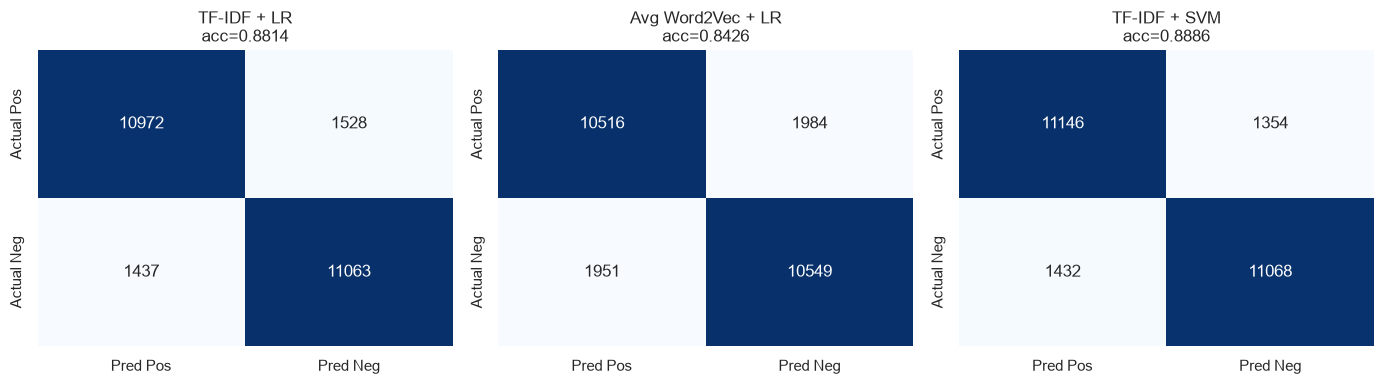

In [8]:
preds_test = {
    "TF-IDF + LR":      base["model"].predict(base["Xte"]),
    "Avg Word2Vec + LR": model_w.predict(Xte_w),
    "TF-IDF + SVM":     svm["model"].predict(svm["Xte"]),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, pr) in zip(axes, preds_test.items()):
    cm = confusion_matrix(test_df.label, pr, labels=[1, 0])        # hàng/cột: Pos, Neg
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred Pos", "Pred Neg"], yticklabels=["Actual Pos", "Actual Neg"])
    acc = accuracy_score(test_df.label, pr)
    ax.set_title(f"{name}\nacc={acc:.4f}")
    print(name, "| TP, FN, FP, TN =", cm.ravel().tolist())
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

In [9]:
y_te = test_df.label.values
for name, pr in preds_test.items():
    tn, fp, fn, tp = confusion_matrix(y_te, pr).ravel()
    print(f"{name:20s} FP={fp:5d} (neg->pos)  FN={fn:5d} (pos->neg)  | precision(pos)={tp/(tp+fp):.4f} recall(pos)={tp/(tp+fn):.4f}")

TF-IDF + LR          FP= 1437 (neg->pos)  FN= 1528 (pos->neg)  | precision(pos)=0.8842 recall(pos)=0.8778
Avg Word2Vec + LR    FP= 1951 (neg->pos)  FN= 1984 (pos->neg)  | precision(pos)=0.8435 recall(pos)=0.8413
TF-IDF + SVM         FP= 1432 (neg->pos)  FN= 1354 (pos->neg)  | precision(pos)=0.8862 recall(pos)=0.8917


### Ảnh hưởng của threshold (liên hệ Bài 2) và accuracy trap (liên hệ Bài 4)

In [10]:
proba_te = base["model"].predict_proba(base["Xte"])[:, 1]
th_rows = []
for tau in (0.3, 0.5, 0.7, 0.8, 0.9):
    p = (proba_te >= tau).astype(int)
    th_rows.append(dict(threshold=tau, **{k: round(v, 4) for k, v in metrics(y_te, p).items()}))
print("TF-IDF + LR trên test, đổi threshold:"); display(pd.DataFrame(th_rows))

# Accuracy trap: lấy tập test mất cân bằng 95% neg / 5% pos
rng = np.random.RandomState(P.SEED)
neg_idx = np.where(y_te == 0)[0]; pos_idx = np.where(y_te == 1)[0]
idx = np.concatenate([rng.choice(neg_idx, 950, replace=False), rng.choice(pos_idx, 50, replace=False)])
dummy = DummyClassifier(strategy="most_frequent").fit(base["Xtr"], train_df.label.map(lambda v: 0))
rows_trap = []
for name, pr in [("always negative", np.zeros(len(idx), dtype=int)), ("TF-IDF + LR", preds_test["TF-IDF + LR"][idx])]:
    rows_trap.append(dict(model=name, **{k: round(v, 4) for k, v in metrics(y_te[idx], pr).items()}))
print("\nTập test mất cân bằng 950 neg / 50 pos:"); display(pd.DataFrame(rows_trap))

TF-IDF + LR trên test, đổi threshold:


,threshold,accuracy,precision,recall,f1
0,0.3,0.8682,0.8206,0.9424,0.8773
1,0.5,0.8814,0.8842,0.8778,0.8810
2,0.7,0.8620,0.9330,0.7799,0.8496
3,0.8,0.8306,0.9522,0.6962,0.8043
4,0.9,0.7686,0.9716,0.5534,0.7051



Tập test mất cân bằng 950 neg / 50 pos:


,model,accuracy,precision,recall,f1
0,always negative,0.950,0.0000,0.0,0.0000
1,TF-IDF + LR,0.887,0.2797,0.8,0.4145


## 6. Các thí nghiệm kiểm chứng prediction: vocabulary size & stopwords
So sánh trên **validation** (không chạm test), TF-IDF unigram + LR với `C` cố định = best C của baseline.

In [11]:
def quick(vec_kw, ngram=(1,1)):
    vec = make_tfidf(ngram_range=ngram, **vec_kw)
    t0 = time.perf_counter(); Xtr = vec.fit_transform(train_df.clean)
    m_ = LogisticRegression(C=base["C"], max_iter=2000, solver="liblinear").fit(Xtr, train_df.label)
    t = time.perf_counter() - t0
    mv = metrics(val_df.label, m_.predict(vec.transform(val_df.clean)))
    return len(vec.vocabulary_), t, mv

out = []
for mf in (1000, 5000, 20000, None):
    v, t, mv = quick(dict(max_features=mf))
    out.append(dict(setting=f"max_features={mf}", vocab=v, time_s=round(t,2), val_acc=round(mv["accuracy"],4), val_f1=round(mv["f1"],4)))
    log("vocab_size", f"TF-IDF max_features={mf}", "LogisticRegression", "val", v, t, mv)
v, t, mv = quick(dict(stop_words="english"))
out.append(dict(setting="remove stopwords (sklearn english)", vocab=v, time_s=round(t,2), val_acc=round(mv["accuracy"],4), val_f1=round(mv["f1"],4)))
log("stopwords", "TF-IDF stopwords removed", "LogisticRegression", "val", v, t, mv)
display(pd.DataFrame(out))
print("Các từ phủ định trong stopword list của sklearn:", sorted(w for w in ENGLISH_STOP_WORDS if w in {"not","no","nor","never","none","nothing","cannot","neither","nobody","very","too"}))

,setting,vocab,time_s,val_acc,val_f1
0,max_features=1000,1000,2.44,0.8595,0.8614
1,max_features=5000,5000,2.76,0.8753,0.8765
2,max_features=20000,20000,2.98,0.8878,0.8893
3,max_features=None,40790,2.93,0.8906,0.8920
4,remove stopwords (sklearn english),40482,2.36,0.8822,0.8841


Các từ phủ định trong stopword list của sklearn: ['cannot', 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing', 'too', 'very']


## 7. Experiment 4 — Word order: "this movie is good" vs "this movie is not good"

In [12]:
pairs = [("this movie is good", "this movie is not good"),
         ("i like this movie", "i do not like this movie"),
         ("the plot is great", "the plot is not great"),
         ("a good film", "not a good film")]

# model bigram (để so sánh): TF-IDF 1-2gram + LR
bi = run_tfidf_lr(ngram=(1,2))

def vec_avg(s):  return P.average_embedding(P.tokenize(s), wv, DIM)
def cos(a, b):   return float(a @ b / (np.linalg.norm(a)*np.linalg.norm(b) + 1e-12))

rows4 = []
for s1, s2 in pairs:
    a, b = vec_avg(s1), vec_avg(s2)
    pw = lambda s: model_w.predict_proba(scaler.transform(vec_avg(s)[None]))[0, 1]
    pu = lambda s: base["model"].predict_proba(base["vec"].transform([s]))[0, 1]
    pb = lambda s: bi["model"].predict_proba(bi["vec"].transform([s]))[0, 1]
    rows4.append({"S1": s1, "S2": s2, "cos(avgW2V S1,S2)": round(cos(a, b), 3),
                  "P(pos) W2V S1": round(pw(s1),3), "P(pos) W2V S2": round(pw(s2),3),
                  "P(pos) TFIDF-uni S1": round(pu(s1),3), "P(pos) TFIDF-uni S2": round(pu(s2),3),
                  "P(pos) TFIDF-bi S1": round(pb(s1),3), "P(pos) TFIDF-bi S2": round(pb(s2),3)})
display(pd.DataFrame(rows4).T)

# bằng chứng định lượng: vector trung bình của S2 = (n1*vec(S1) + vec(not)) / (n1+1)
s1, s2 = pairs[0]
a, b = vec_avg(s1), vec_avg(s2)
n1 = len(P.tokenize(s1))
print("\n||avg(S2) - ((n1*avg(S1) + v_not)/(n1+1))|| =", float(np.linalg.norm(b - (n1*a + wv['not'])/(n1+1))), "(≈ 0: 'not' chỉ được cộng vào vector rồi chia trung bình)")
print("Trọng số LR (unigram) của 'good':", round(float(base['model'].coef_[0][base['vec'].vocabulary_['good']]),3),
      "| 'not':", round(float(base['model'].coef_[0][base['vec'].vocabulary_['not']]),3))
vb = bi["vec"].vocabulary_
for g in ("not good", "very good", "not bad"):
    print(f"Trọng số LR (bigram) của '{g}':", round(float(bi['model'].coef_[0][vb[g]]),3) if g in vb else "n/a")

,0,1,2,3
S1,this movie is good,i like this movie,the plot is great,a good film
S2,this movie is not good,i do not like this movie,the plot is not great,not a good film
"cos(avgW2V S1,S2)",0.948,0.922,0.914,0.923
P(pos) W2V S1,0.991,0.91,0.735,1.0
P(pos) W2V S2,0.851,0.043,0.234,0.998
P(pos) TFIDF-uni S1,0.934,0.19,0.996,0.988
P(pos) TFIDF-uni S2,0.503,0.02,0.961,0.759
P(pos) TFIDF-bi S1,0.997,0.625,1.0,0.999
P(pos) TFIDF-bi S2,0.003,0.475,0.843,0.278



||avg(S2) - ((n1*avg(S1) + v_not)/(n1+1))|| = 4.825388373319583e-07 (≈ 0: 'not' chỉ được cộng vào vector rồi chia trung bình)
Trọng số LR (unigram) của 'good': 4.609 | 'not': -4.933
Trọng số LR (bigram) của 'not good': -6.472
Trọng số LR (bigram) của 'very good': 6.484
Trọng số LR (bigram) của 'not bad': 5.642


## 8. Experiment 5 — n-gram features: unigram vs unigram + bigram

In [13]:
rows5 = []
for name, ng, run in [("Unigram", (1,1), base), ("Uni + Bigram", (1,2), bi)]:
    pt = metrics(test_df.label, run["model"].predict(run["Xte"]))
    pv = metrics(val_df.label, run["model"].predict(run["Xva"]))
    rows5.append({"Features": name, "Vocabulary": run["vocab"], "Val F1": round(pv["f1"],4),
                  "Test F1": round(pt["f1"],4), "Test Acc": round(pt["accuracy"],4), "Training time (s)": round(run["t_train"],2), "best C": run["C"]})
    log("ngram", f"TF-IDF {name}", "LogisticRegression", "test", run["vocab"], run["t_train"], pt)
    log("ngram", f"TF-IDF {name}", "LogisticRegression", "val", run["vocab"], run["t_train"], pv)
display(pd.DataFrame(rows5))

,Features,Vocabulary,Val F1,Test F1,Test Acc,Training time (s),best C
0,Unigram,40790,0.8920,0.8810,0.8814,3.13,10
1,Uni + Bigram,364040,0.9041,0.9023,0.9022,9.32,100


## 9. Model interpretation — top features của Logistic Regression + TF-IDF

Top positive features (unigram):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
feature,great,excellent,perfect,wonderful,best,amazing,brilliant,superb,today,enjoyable,favorite,highly,subtle,rare,enjoyed,wonderfully,loved,funniest,perfectly,well
weight,11.453,10.486,9.064,7.677,7.65,6.998,6.582,6.516,6.511,6.462,6.235,6.207,6.175,6.028,6.021,5.95,5.89,5.806,5.767,5.751


Top negative features (unigram):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
feature,worst,waste,bad,awful,boring,disappointment,poorly,poor,worse,fails,avoid,dull,terrible,save,nothing,unfortunately,disappointing,annoying,horrible,lacks
weight,-15.102,-11.477,-11.46,-11.361,-10.342,-9.3,-9.012,-8.738,-8.055,-7.684,-7.67,-7.564,-7.517,-7.484,-7.452,-7.34,-7.019,-6.949,-6.932,-6.868


Top positive features (uni+bigram):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
feature,great,excellent,perfect,wonderful,amazing,the best,brilliant,fun,best,today,enjoyable,superb,love,loved,favorite,definitely,enjoyed,rare,better than,bit
weight,20.537,15.934,13.558,13.14,11.321,10.866,10.239,10.095,9.936,9.871,9.681,9.403,9.346,9.225,9.164,8.534,8.478,8.436,8.383,8.248


Top negative features (uni+bigram):


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
feature,bad,worst,awful,boring,the worst,poor,waste,worse,poorly,terrible,disappointment,no,nothing,dull,unfortunately,annoying,disappointing,horrible,stupid,lame
weight,-21.672,-20.296,-17.819,-17.417,-15.655,-15.394,-14.392,-12.813,-12.493,-12.297,-12.258,-12.243,-12.2,-11.999,-11.461,-11.268,-10.954,-10.814,-10.683,-10.568


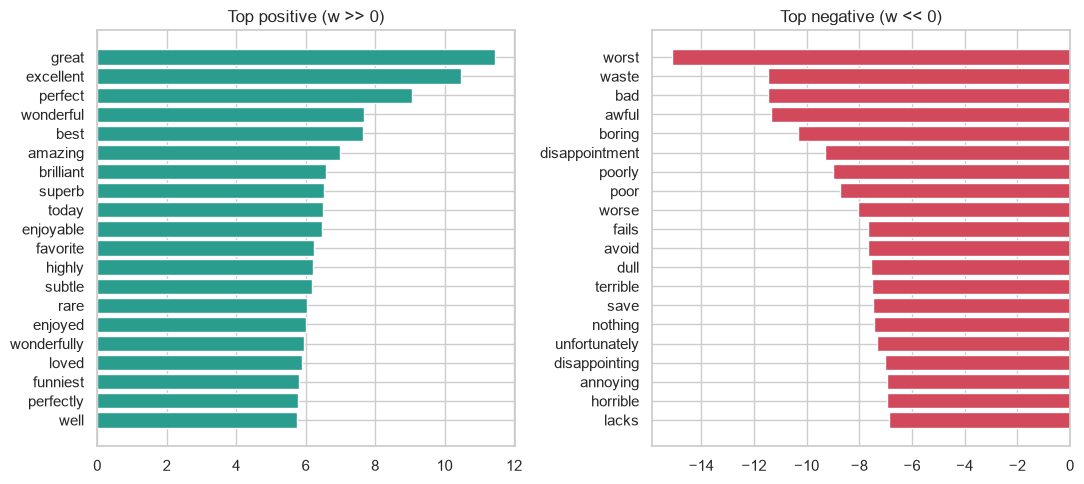

In [14]:
def top_features(run, k=20):
    names = np.array(run["vec"].get_feature_names_out()); w = run["model"].coef_[0]
    order = np.argsort(w)
    return (pd.DataFrame({"feature": names[order[::-1][:k]], "weight": w[order[::-1][:k]].round(3)}),
            pd.DataFrame({"feature": names[order[:k]], "weight": w[order[:k]].round(3)}))
pos_f, neg_f = top_features(base)
print("Top positive features (unigram):"); display(pos_f.T)
print("Top negative features (unigram):"); display(neg_f.T)
pos_b, neg_b = top_features(bi)
print("Top positive features (uni+bigram):"); display(pos_b.T)
print("Top negative features (uni+bigram):"); display(neg_b.T)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].barh(pos_f.feature[::-1], pos_f.weight[::-1], color="#2a9d8f"); ax[0].set_title("Top positive (w >> 0)")
ax[1].barh(neg_f.feature[::-1], neg_f.weight[::-1], color="#d1495b"); ax[1].set_title("Top negative (w << 0)")
plt.tight_layout(); plt.savefig("top_features.png", dpi=150); plt.show()

## 10. Error analysis — mẫu đúng/sai của baseline (TF-IDF + LR) trên test

In [15]:
pr_b = preds_test["TF-IDF + LR"]
test_df["pred"] = pr_b
test_df["p_pos"] = proba_te
test_df["n_words"] = test_df.clean.str.split().str.len()
test_df["correct"] = test_df.pred == test_df.label

errs = test_df[~test_df.correct]
print("Số lỗi:", len(errs), "| FP (neg->pos):", ((errs.label==0)).sum(), "| FN (pos->neg):", ((errs.label==1)).sum())
print("Độ dài trung bình (từ): đúng =", round(test_df[test_df.correct].n_words.mean(),1), "| sai =", round(errs.n_words.mean(),1))

short = test_df[test_df.n_words <= 40]
print(f"\nReview ngắn (<=40 từ): {len(short)} mẫu, accuracy = {short.correct.mean():.4f}  vs toàn test {test_df.correct.mean():.4f}")

# thống kê nhanh các hiện tượng gợi ý cho phân loại lỗi
neg_words = r"\b(?:not|no|never|n't|nothing|hardly|barely)\b|n't"
errs = errs.assign(has_negation=errs.clean.str.contains(neg_words, regex=True),
                   has_sarcasm_cue=errs.clean.str.contains(r"\b(?:oh great|yeah right|thanks for|wow just)\b", regex=True))
print("Tỉ lệ lỗi có từ phủ định:", round(errs.has_negation.mean(), 3), "| tỉ lệ review nói chung có phủ định:", round(test_df.clean.str.contains(neg_words, regex=True).mean(), 3))

def show(df, title, n=3, seed=P.SEED, maxlen=700):
    print("\n" + "="*20, title, "="*20)
    for i, r in df.sample(n, random_state=seed).iterrows():
        print(f"[idx={i}] true={r.label} pred={r.pred} P(pos)={r.p_pos:.3f} words={r.n_words}\n  {r.text[:maxlen]}\n")

mid = test_df[(test_df.n_words <= 120)]
show(mid[mid.correct & (mid.label == 1)], "ĐÚNG – positive", 2)
show(mid[mid.correct & (mid.label == 0)], "ĐÚNG – negative", 2)
show(mid[(~mid.correct) & (mid.label == 0)], "SAI – FP (thật negative, đoán positive)", 4)
show(mid[(~mid.correct) & (mid.label == 1)], "SAI – FN (thật positive, đoán negative)", 4)

Số lỗi: 2965 | FP (neg->pos): 1437 | FN (pos->neg): 1528
Độ dài trung bình (từ): đúng = 228.1 | sai = 230.5

Review ngắn (<=40 từ): 224 mẫu, accuracy = 0.8750  vs toàn test 0.8814


Tỉ lệ lỗi có từ phủ định: 0.883 | tỉ lệ review nói chung có phủ định: 0.882

==================== ĐÚNG – positive ====================
[idx=18257] true=1 pred=1 P(pos)=0.967 words=90
  What gives this movie its personality is the knowledge, in the end, that it is all true. While it is a compelling and humorous documentary that does border on mockumentary in some parts (are they staged or is it really happening humorously?), it does seem to get a bit long towards the end.<br /><br />This movie is funny in places it needs to be, and flows relatively well. Reminiscent of Christopher Guest's movies, if you liked those or Adaptation then I recommend you keep a look out for this one.<br /><br />B+

[idx=19241] true=1 pred=1 P(pos)=0.957 words=19
  Without a doubt, one of Tobe Hoppor's best! Epic storytellng, great special effects, and The Spacegirl (vamp me baby!).


==================== ĐÚNG – negative ====================
[idx=1796] true=0 pred=0 P(pos)=0.003 words=109
  I'm not sure why I

## 11. Lưu kết quả

In [16]:
res = pd.DataFrame(rows)
res.to_csv("results.csv", index=False)
print(res.shape); display(res)

(15, 10)


,experiment,representation,classifier,split,feature_dim,train_time_s,accuracy,precision,recall,f1
0,baseline,TF-IDF (unigram),LogisticRegression,val,40790,3.128,0.8906,0.8824,0.9018,0.8920
1,baseline,TF-IDF (unigram),LogisticRegression,test,40790,3.128,0.8814,0.8842,0.8778,0.8810
2,representation,Avg Word2Vec,LogisticRegression,val,100,51.911,0.8416,0.8353,0.8517,0.8434
3,representation,Avg Word2Vec,LogisticRegression,test,100,51.911,0.8426,0.8435,0.8413,0.8424
4,representation,TF-IDF (unigram),LinearSVC,val,40790,2.218,0.8916,0.8811,0.9058,0.8933
5,representation,TF-IDF (unigram),LinearSVC,test,40790,2.218,0.8886,0.8862,0.8917,0.8889
6,vocab_size,TF-IDF max_features=1000,LogisticRegression,val,1000,2.436,0.8595,0.8513,0.8717,0.8614
7,vocab_size,TF-IDF max_features=5000,LogisticRegression,val,5000,2.757,0.8753,0.8698,0.8834,0.8765
8,vocab_size,TF-IDF max_features=20000,LogisticRegression,val,20000,2.979,0.8878,0.8787,0.9002,0.8893
9,vocab_size,TF-IDF max_features=None,LogisticRegression,val,40790,2.931,0.8906,0.8824,0.9018,0.8920
